# TP 3 : Vision par ordinateur
**Module :** Technologies IA | **Prof :** Youness IDRISSI KHAMLICHI
**Étudiant :** EL-ABBADI MOHAMMED, N° 16 | **Filière :** Ingénierie Logicielle et Intelligence Artificielle (ILIA2), ENSA Fès

> Environnement recommandé : **Google Colab (GPU)**. Les images (`image1.jpg`, `image_objects.jpg`, `people.jpg`, `ref.jpg`, `test.jpg`) sont à uploader dans la session (ou à placer dans le dossier `images/`).

## 0. Installation et fonctions utilitaires

In [23]:
!pip install -q opencv-python numpy matplotlib ultralytics
!apt-get install -y -q cmake libopenblas-dev liblapack-dev
!pip install -q dlib-bin face_recognition

Reading package lists...
Building dependency tree...
Reading state information...
cmake is already the newest version (3.28.3-1build7).
libopenblas-dev is already the newest version (0.3.26+ds-1ubuntu0.1).
liblapack-dev is already the newest version (3.12.0-3build1.1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [24]:
import cv2, os
for nom in ["image_objects", "people", "ref", "test"]:
    if os.path.exists(nom + ".png"):
        cv2.imwrite(nom + ".jpg", cv2.imread(nom + ".png"))
        print(nom, "-> converti en .jpg")

image_objects -> converti en .jpg
people -> converti en .jpg
ref -> converti en .jpg
test -> converti en .jpg


In [25]:
requis = ["image1.jpg", "image_objects.jpg", "people.jpg", "ref.jpg", "test.jpg"]
manquants = [f for f in requis if not os.path.exists(f)]
if manquants:
    print("Fichiers manquants :", manquants)
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass
else:
    print("Toutes les images sont présentes.")

Toutes les images sont présentes.


---
# Partie 1 : Concepts de base
## Exercice 1 : Analyse d'une image

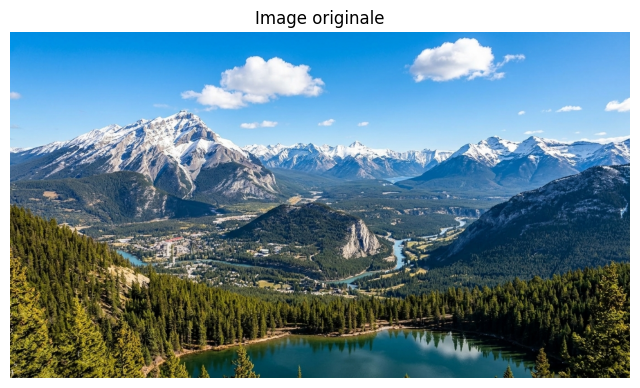

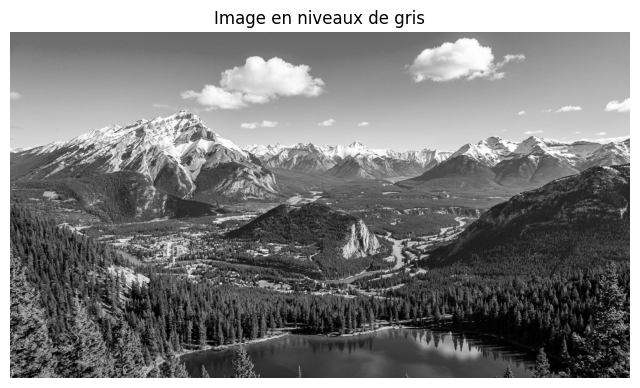

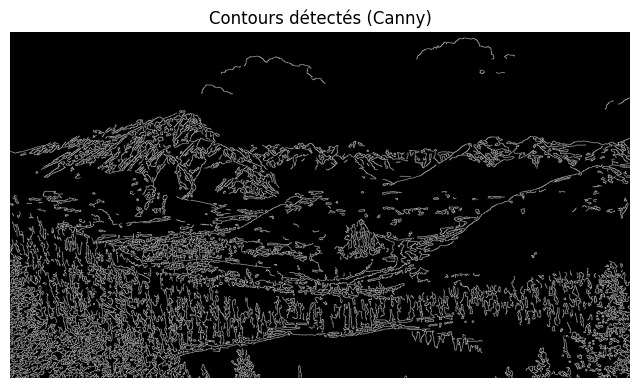

Forme image couleur : (768, 1376, 3) | dtype : uint8
Forme image grise   : (768, 1376)


In [26]:
IMG1 = "image1.jpg"


img = cv2.imread(IMG1)
assert img is not None, f"Image '{IMG1}' introuvable"
show(img, "Image originale")


gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
show(gray, "Image en niveaux de gris", gray=True)


blur = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blur, 100, 200)
show(edges, "Contours détectés (Canny)", gray=True)

print("Forme image couleur :", img.shape, "| dtype :", img.dtype)
print("Forme image grise   :", gray.shape)

### Réponses aux questions
**1. Que représente la matrice retournée par OpenCV ?**
C'est un tableau NumPy de forme `(hauteur, largeur, 3)` et de type `uint8`. Chaque case contient l'intensité (0 à 255) d'un pixel pour un canal de couleur. Attention : OpenCV utilise l'ordre **BGR** (et non RGB). Une image en niveaux de gris est une matrice 2D `(hauteur, largeur)`.

**2. Pourquoi convertit-on souvent en niveaux de gris avant traitement ?**
- On passe de 3 canaux à 1 : **3 fois moins de données**, donc calculs plus rapides et moins de mémoire.
- La plupart des algorithmes (contours, détection de visages HOG/Haar, descripteurs) reposent sur les **variations d'intensité** (gradients) et non sur la couleur.
- Cela rend le traitement plus robuste aux variations de couleur et simplifie les algorithmes.

**3. Que peut nous apporter le filtre Gaussien ?** (`cv2.GaussianBlur(gray, (5, 5), 0)`)
Il **lisse l'image** en faisant une moyenne pondérée gaussienne des pixels voisins (noyau 5x5, l'écart-type σ est calculé automatiquement quand il vaut 0). Il **réduit le bruit** et les petits détails parasites, ce qui évite à Canny de détecter de faux contours. Contrepartie : les contours deviennent un peu moins nets si le noyau est trop grand.

---
# Partie 2 : Traitement d'images et vidéos
## Exercice 2 : Lecture vidéo / webcam
Une seule fonction gère la **webcam** (`source=0`) ou un **fichier vidéo**, applique le filtre gris en temps réel, quitte avec `q` et enregistre la vidéo traitée.

100 images traitées -> sortie_gris.mp4


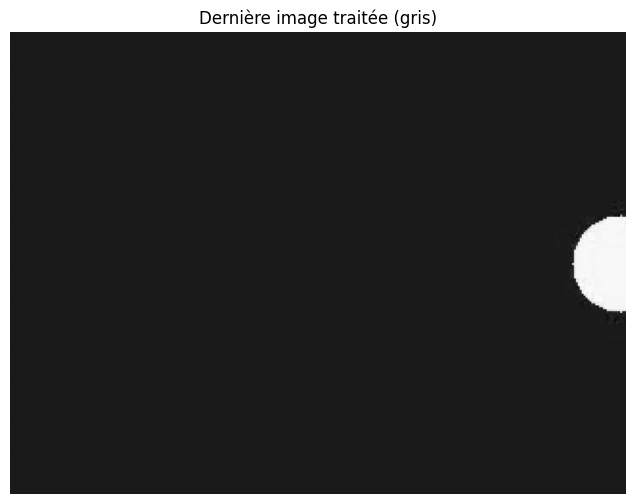

In [27]:
def traiter_video(source=0, sortie="sortie_gris.mp4", afficher=True, max_frames=None):
    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        raise RuntimeError(f"Impossible d'ouvrir la source : {source}")
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 20.0
    out = cv2.VideoWriter(sortie, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h), isColor=False)

    n, derniere = 0, None
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        out.write(gray)
        derniere = gray
        n += 1
        if afficher:
            cv2.imshow("Webcam (gris) - q pour quitter", gray)
            if cv2.waitKey(int(1000 / fps)) & 0xFF == ord("q"):
                break
        if max_frames and n >= max_frames:
            break
    cap.release(); out.release(); cv2.destroyAllWindows()
    print(f"{n} images traitées -> {sortie}")
    return derniere


SOURCE = "video.mp4"
if not os.path.exists(SOURCE):
    vw = cv2.VideoWriter(SOURCE, cv2.VideoWriter_fourcc(*"mp4v"), 20, (320, 240))
    for i in range(100):
        f = np.full((240, 320, 3), (40, 120, 200), np.uint8)
        cv2.circle(f, (20 + 3 * i, 120), 25, (0, 255, 255), -1)
        vw.write(f)
    vw.release()

derniere = traiter_video(SOURCE, "sortie_gris.mp4", afficher=False)
show(derniere, "Dernière image traitée (gris)", gray=True)



### Réponse à la question
**Que se passe-t-il avec une vidéo enregistrée à la place de la webcam ?**
- On remplace `VideoCapture(0)` par `VideoCapture("video.mp4")`.
- La vidéo a une **fin** : `cap.read()` renvoie `ret = False` à la dernière image et la boucle s'arrête d'elle-même (une webcam, elle, tourne tant qu'on ne l'arrête pas).
- Le FPS vient du fichier (`CAP_PROP_FPS`). Avec `waitKey(1)` la lecture va **plus vite** que la vidéo réelle : il faut un délai de `1000/fps` ms pour respecter la vitesse d'origine.
- On peut rejouer exactement les mêmes images, utile pour tester et comparer des algorithmes (reproductibilité).

---
# Partie 3 : Détection et segmentation avec Detectron2
## Exercice 3 : Mask R-CNN

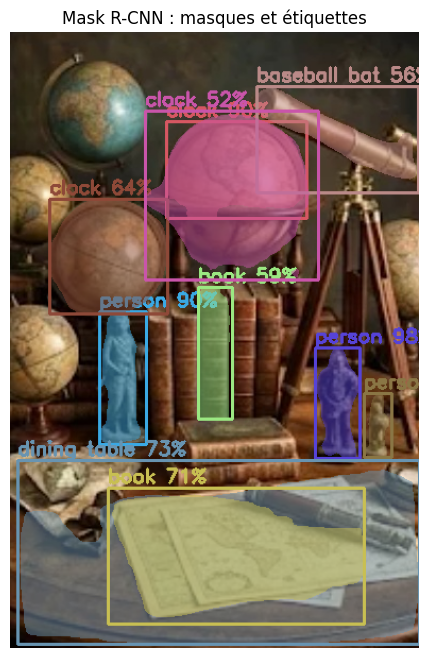

In [28]:
import torch, time
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

device = "cuda" if torch.cuda.is_available() else "cpu"
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
model_mrcnn = maskrcnn_resnet50_fpn(weights=weights).to(device).eval()
classes = weights.meta["categories"]

@torch.no_grad()
def predict(img_bgr, seuil=0.5):
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    t = torch.from_numpy(rgb).permute(2, 0, 1).float().div(255).to(device)
    out = model_mrcnn([t])[0]
    keep = out["scores"] >= seuil
    return {k: v[keep].cpu() for k, v in out.items()}

def dessiner(img_bgr, res, alpha=0.5):
    out = img_bgr.copy()
    rng = np.random.default_rng(3)
    for box, label, score, mask in zip(res["boxes"], res["labels"], res["scores"], res["masks"]):
        color = rng.integers(50, 255, 3).tolist()
        m = mask[0].numpy() > 0.5
        out[m] = (out[m] * (1 - alpha) + np.array(color) * alpha).astype(np.uint8)
        x1, y1, x2, y2 = box.int().tolist()
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
        cv2.putText(out, f"{classes[int(label)]} {float(score):.0%}", (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return out

IMG_OBJ = "image_objects.jpg"
img_obj = cv2.imread(IMG_OBJ)
res = predict(img_obj, 0.5)
show(dessiner(img_obj, res), "Mask R-CNN : masques et étiquettes", size=(10, 8))

In [29]:
for l, s in zip(res["labels"].tolist(), res["scores"].tolist()):
    print(f"{classes[l]:<15} {s:.0%}")

person          98%
clock           90%
person          90%
person          86%
dining table    73%
book            71%
clock           64%
book            59%
baseball bat    56%
clock           52%


Seuil 0.2: 17 objets -> ['person', 'clock', 'person', 'person', 'dining table', 'book', 'clock', 'book', 'baseball bat', 'clock', 'person', 'sports ball', 'backpack', 'book', 'chair', 'bicycle', 'book']


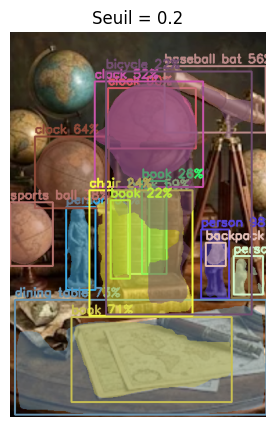

Seuil 0.5: 10 objets -> ['person', 'clock', 'person', 'person', 'dining table', 'book', 'clock', 'book', 'baseball bat', 'clock']


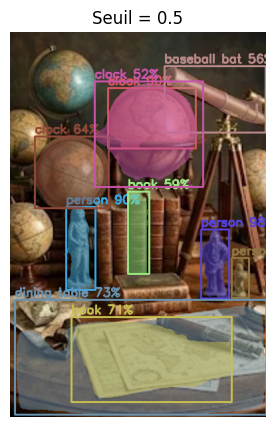

Seuil 0.7: 6 objets -> ['person', 'clock', 'person', 'person', 'dining table', 'book']


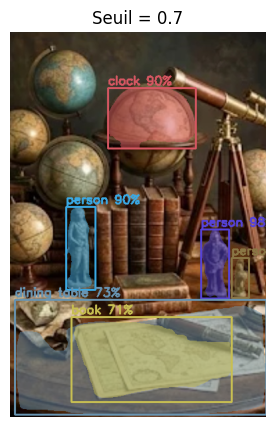

Seuil 0.9: 2 objets -> ['person', 'clock']


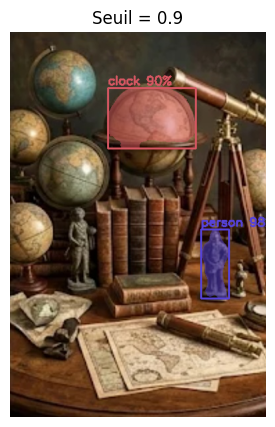

In [30]:
res_all = predict(img_obj, 0.05)
for seuil in [0.2, 0.5, 0.7, 0.9]:
    keep = res_all["scores"] >= seuil
    sel = {k: v[keep] for k, v in res_all.items()}
    noms = [classes[int(l)] for l in sel["labels"]]
    print(f"Seuil {seuil}: {len(noms)} objets -> {noms}")
    show(dessiner(img_obj, sel), f"Seuil = {seuil}", size=(7, 5))

### Réponses aux questions
**1. Quels objets ont été détectés ?**
Sur l'exemple du TP : des `person` (scores 70 à 100 %) et des `tie` (cravates, ~98-100 %). Sur les autres images : un oiseau (`bird`), un `cat` pour un chien, un `zebra` pour un tigre : le modèle est entraîné sur les 80 classes de **COCO**, qui ne contient ni tigre ni perroquet précis. Il assigne donc la classe la plus proche, avec un score plus faible (56 à 88 %). *(Compléter avec la sortie exacte obtenue sur votre image.)*

**2. Effet du seuil `SCORE_THRESH_TEST` ?**
- **Seuil bas (0.2)** : plus de détections (meilleur rappel) mais plus de **faux positifs** et d'objets en doublon.
- **Seuil élevé (0.9)** : seules les détections très sûres restent (haute précision) mais on **rate des objets** (faux négatifs).
- 0.5 est un compromis ; le bon seuil dépend de l'application (sécurité : seuil bas, affichage propre : seuil élevé).

---
# Partie 4 : Détection et reconnaissance faciale
## Exercice 4 : Détection faciale (Dlib)

Visages détectés : 7


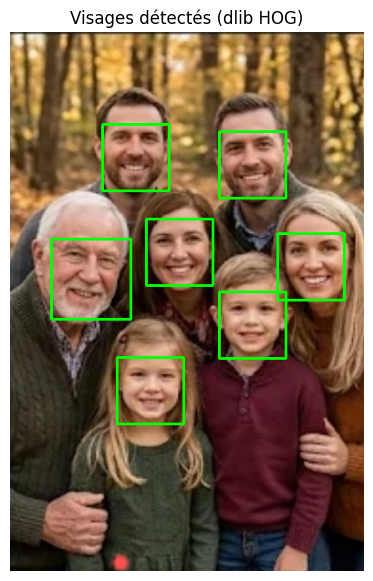

In [31]:
import dlib

detector = dlib.get_frontal_face_detector()
img = cv2.imread("people.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = detector(gray)
print("Visages détectés :", len(faces))
for face in faces:
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)

show(img, "Visages détectés (dlib HOG)", size=(10, 7))

## Exercice 5 : Reconnaissance faciale (face_recognition)
Chaque visage est transformé en un **vecteur de 128 valeurs** (encodage). Deux visages sont jugés identiques si la distance euclidienne entre leurs vecteurs est inférieure à la tolérance (0.6 par défaut).

In [32]:
import face_recognition
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

REF, TEST = "ref.jpg", "test.jpg"
image_ref = face_recognition.load_image_file(REF)
image_test = face_recognition.load_image_file(TEST)

enc_ref = face_recognition.face_encodings(image_ref)
enc_test = face_recognition.face_encodings(image_test)
assert enc_ref, "Aucun visage trouvé dans l'image de référence"
assert enc_test, "Aucun visage trouvé dans l'image test"

print("Visages dans l'image test :", len(enc_test))
resultats = face_recognition.compare_faces(enc_test, enc_ref[0], tolerance=0.6)
distances = face_recognition.face_distance(enc_test, enc_ref[0])
for i, (ok, d) in enumerate(zip(resultats, distances)):
    print(f"Visage {i}: même personne ? {ok} (distance = {d:.3f})")
print("Même personne ?", any(resultats))

Visages dans l'image test : 1
Visage 0: même personne ? True (distance = 0.416)
Même personne ? True


### Réponses aux questions
**1. Que se passe-t-il si l'image test contient plusieurs visages ?**
`face_encodings()` renvoie **une liste** avec un encodage par visage. Avec `[0]` (code du TP), seul le *premier* visage détecté est comparé : si la personne cherchée est un autre visage, on obtient un faux `False`. Et si aucun visage n'est détecté, `[0]` provoque une `IndexError`. La bonne approche : comparer la référence à **tous** les encodages (cellule ci-dessus) et utiliser `face_distance` pour retenir le plus proche.

**2. Précision attendue en conditions réelles ?**
Le modèle de dlib annonce environ **99,4 %** sur le benchmark LFW (photos de bonne qualité, visages de face). En conditions réelles la précision est **nettement plus faible** à cause : de l'éclairage (ombres, contre-jour), des angles/poses, des occlusions (masque, lunettes, casquette), de la résolution, de l'âge entre les photos, des expressions. Il faut ajuster la tolérance (0.5 plus strict, 0.6 plus permissif) : un seuil trop permissif crée des faux positifs, un seuil trop strict des faux négatifs. Pour un usage sensible (accès, sécurité), il faut des tests sur ses propres données.

## Exercice 6 : Points caractéristiques (landmarks)

Visages : 7
Parties retournées : ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']


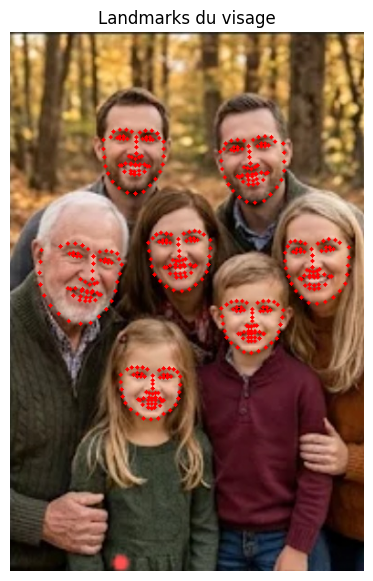

In [33]:
img = cv2.imread("people.jpg")
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
landmarks_list = face_recognition.face_landmarks(rgb)
print("Visages :", len(landmarks_list))
print("Parties retournées :", list(landmarks_list[0].keys()))

for landmarks in landmarks_list:
    for partie, points in landmarks.items():
        for (x, y) in points:
            cv2.circle(img, (x, y), 2, (0, 0, 255), -1)
show(img, "Landmarks du visage", size=(10, 7))

In [34]:

def distance(p, q):
    return np.linalg.norm(np.array(p) - np.array(q))

def ear(oeil):

    A = distance(oeil[1], oeil[5])
    B = distance(oeil[2], oeil[4])
    C = distance(oeil[0], oeil[3])
    return (A + B) / (2.0 * C)

for i, lm in enumerate(landmarks_list):
    e_g, e_d = ear(lm["left_eye"]), ear(lm["right_eye"])
    print(f"Visage {i}: EAR gauche = {e_g:.2f}, droit = {e_d:.2f}, moyen = {(e_g + e_d) / 2:.2f}")

Visage 0: EAR gauche = 0.25, droit = 0.26, moyen = 0.26
Visage 1: EAR gauche = 0.29, droit = 0.25, moyen = 0.27
Visage 2: EAR gauche = 0.30, droit = 0.27, moyen = 0.28
Visage 3: EAR gauche = 0.27, droit = 0.27, moyen = 0.27
Visage 4: EAR gauche = 0.34, droit = 0.37, moyen = 0.35
Visage 5: EAR gauche = 0.29, droit = 0.25, moyen = 0.27
Visage 6: EAR gauche = 0.25, droit = 0.26, moyen = 0.25


### Réponses aux questions
**1. Parties retournées par `face_landmarks` ?**
Un dictionnaire de **9 zones** (68 points au total) : `chin` (contour/menton), `left_eyebrow`, `right_eyebrow`, `nose_bridge`, `nose_tip`, `left_eye`, `right_eye` (6 points chacun), `top_lip`, `bottom_lip`.

**2. EAR : clignement et somnolence ?**
`EAR = (‖p2−p6‖ + ‖p3−p5‖) / (2·‖p1−p4‖)` : rapport entre la **hauteur** et la **largeur** de l'œil. Œil ouvert : EAR ≈ 0.25 à 0.35 (stable). Œil fermé : EAR → ~0.
- **Clignement** : l'EAR passe sous un seuil (≈ 0.2) pendant **2 à 3 images consécutives** puis remonte.
- **Somnolence** : l'EAR reste sous le seuil **longtemps** (ex. > 2 secondes, soit `2 × fps` images) ou le nombre de clignements/le pourcentage de temps œil fermé (PERCLOS) augmente : on déclenche alors une alarme.
- On moyenne les deux yeux, et on calibre le seuil par personne (forme des yeux, lunettes).

---
## Exercice 7 : YOLO vs Mask R-CNN


image 1/1 /content/image_objects.jpg: 640x448 (no detections), 7.1ms
Speed: 1.7ms preprocess, 7.1ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 448)


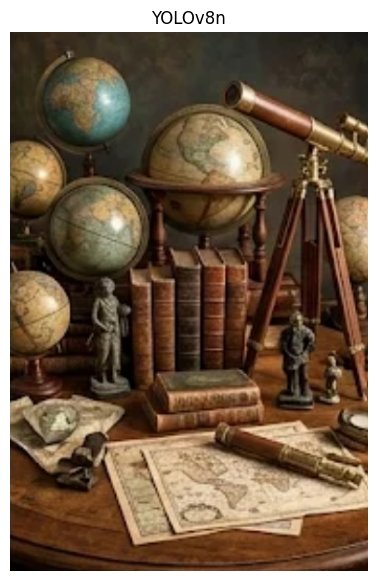

In [35]:
from ultralytics import YOLO

image_path = "image_objects.jpg"
if not os.path.exists(image_path):
    print(f"'{image_path}' non trouvé. Utilisation de 'people.jpg' à la place.")
    image_path = "people.jpg"

model = YOLO("yolov8n.pt")
results = model(image_path, conf=0.5)
show(results[0].plot(), "YOLOv8n", size=(10, 7))

In [36]:
import time, torch, cv2, os
from ultralytics import YOLO
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

device = "cuda" if torch.cuda.is_available() else "cpu"

if "model_mrcnn" not in globals():
    model_mrcnn = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT).to(device).eval()
if "model" not in globals():
    model = YOLO("yolov8n.pt")

image_path = "image_objects.jpg" if os.path.exists("image_objects.jpg") else "people.jpg"
img_test = cv2.imread(image_path)
N = 5

def run_mrcnn():
    rgb = cv2.cvtColor(img_test, cv2.COLOR_BGR2RGB)
    t = torch.from_numpy(rgb).permute(2, 0, 1).float().div(255).to(device)
    with torch.no_grad():
        return model_mrcnn([t])[0]

def run_yolo():
    return model(img_test, conf=0.5, verbose=False)

def chrono(f, n=N):
    f()
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n):
        f()
    if device == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / n

t_yolo = chrono(run_yolo)
t_mask = chrono(run_mrcnn)

print(f"Image : {image_path} | Appareil : {device}")
print(f"YOLOv8n    : {t_yolo * 1000:.0f} ms / image")
print(f"Mask R-CNN : {t_mask * 1000:.0f} ms / image")
print(f"YOLO est ~{t_mask / t_yolo:.1f}x plus rapide")

Image : image_objects.jpg | Appareil : cuda
YOLOv8n    : 12 ms / image
Mask R-CNN : 170 ms / image
YOLO est ~14.7x plus rapide



image 1/1 /content/image_objects.jpg: 640x448 1 person, 9.3ms
Speed: 1.6ms preprocess, 9.3ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 448)


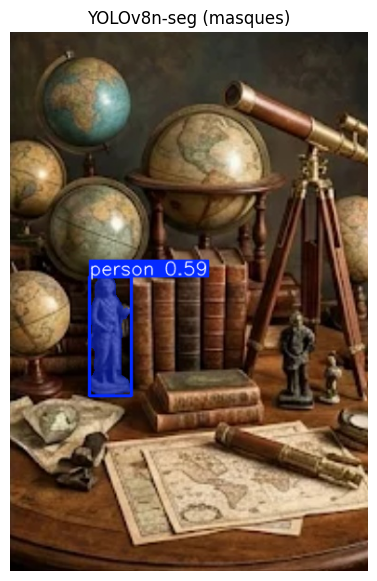

Masques : torch.Size([1, 640, 448])


In [37]:

model_seg = YOLO("yolov8n-seg.pt")
res_seg = model_seg(image_path, conf=0.5)
show(res_seg[0].plot(), "YOLOv8n-seg (masques)", size=(10, 7))
print("Masques :", None if res_seg[0].masks is None else res_seg[0].masks.data.shape)

### Réponses aux questions
**1. Temps d'inférence** : voir la cellule ci-dessus (valeurs à reporter ici après exécution). En général YOLOv8n est **plusieurs fois plus rapide** que Mask R-CNN (quelques dizaines de ms contre plusieurs centaines de ms sur GPU Colab).

**2. YOLO fournit-il des masques ?** Le modèle de base `yolov8n.pt` donne uniquement des **boîtes englobantes**. La variante **`yolov8n-seg.pt`** fournit aussi des **masques de segmentation d'instance** (`results[0].masks`).

**3. Quel modèle choisir ?**

| | **YOLO** | **Mask R-CNN** |
|---|---|---|
| Vitesse | Très rapide (temps réel) | Plus lent (2 étapes) |
| Précision des contours | Correcte (version -seg) | Masques très précis |
| Cas d'usage | Vidéo, webcam, embarqué, comptage, surveillance | Analyse d'images fixes, imagerie médicale, mesures précises d'objets |
| Ressources | Léger | Lourd (GPU conseillé) |

---
# Mini-projet : floutage automatique des visages
Voir le dossier `mini_projet/` (script `flou_visages.py` + README). Démonstration rapide ci-dessous :

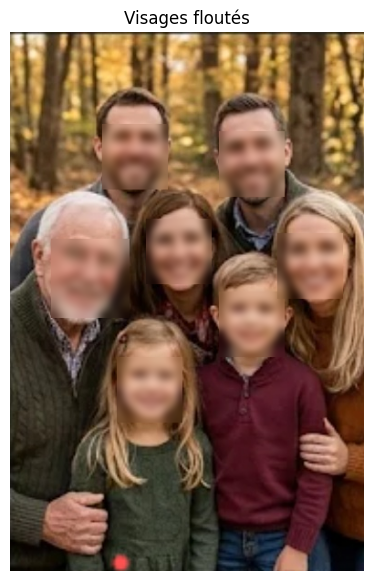

In [38]:
img = cv2.imread("people.jpg")
detector = dlib.get_frontal_face_detector()
for face in detector(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)):
    x1, y1 = max(face.left(), 0), max(face.top(), 0)
    x2, y2 = min(face.right(), img.shape[1]), min(face.bottom(), img.shape[0])
    k = max(3, ((x2 - x1) // 3) | 1)
    img[y1:y2, x1:x2] = cv2.GaussianBlur(img[y1:y2, x1:x2], (k, k), 0)
show(img, "Visages floutés", size=(10, 7))